# 모델 선택 기준

**이 노트북에서 할 일**

1. 모델 카드에서 읽은 후보 다섯 개를 작업 종류와 라이선스로 거릅니다.
2. 남은 생성 모델 두 개를 불러와, 같은 평가 자료로 정답 수와 답 시간을 기록합니다.
3. 평가 자료의 언어와 메모리 기준을 바꿔 보고, 미리 정한 기준으로 후보를 고릅니다.

**준비물** — API 키는 필요 없습니다. 인터넷 서비스의 모델을 부르지 않고, 내 컴퓨터에서 작은 언어 모델 두 개를 실행합니다.
그래서 비용은 들지 않습니다. 모델이 답을 만드는 계산은 모두 16번 합니다.

실행 시간은 1분 안팎입니다. Qwen 모델 파일은 03~07절과 같은 약 1GB(954MiB)입니다.
SmolLM2 모델은 이 절에서 처음 씁니다. 캐시에 없으면 약 270MB를 Hugging Face 사이트에서 내려받습니다.
노트북과 같은 계산을 스크립트로 실행했을 때 Python이 쓴 메모리는 최대 약 3.4GB였습니다.

**기준 버전** — 실습 폴더에 고정한 transformers 4.56.2와 torch 2.8.0을 씁니다.
모델 `Qwen/Qwen2.5-0.5B-Instruct`는 판 번호 `7ae557604adf67be50417f59c2c2f167def9a775`로 받습니다.
모델 `HuggingFaceTB/SmolLM2-135M-Instruct`는 판 번호 `12fd25f77366fa6b3b4b768ec3050bf629380bac`로 받습니다.

후보 표의 작업 종류와 라이선스는 2026-09-16에 Hugging Face 모델 카드에서 확인한 값입니다. 모델 카드는 나중에 바뀔 수 있습니다.
교재 출력은 Linux(aarch64)의 Python 3.12.13과 CPU용 torch(2.8.0+cpu)로 만들었습니다. 다른 버전, GPU, Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part1/ch05-llm-principles`에서 01절과 같은 `.venv` 커널을 고른 뒤 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

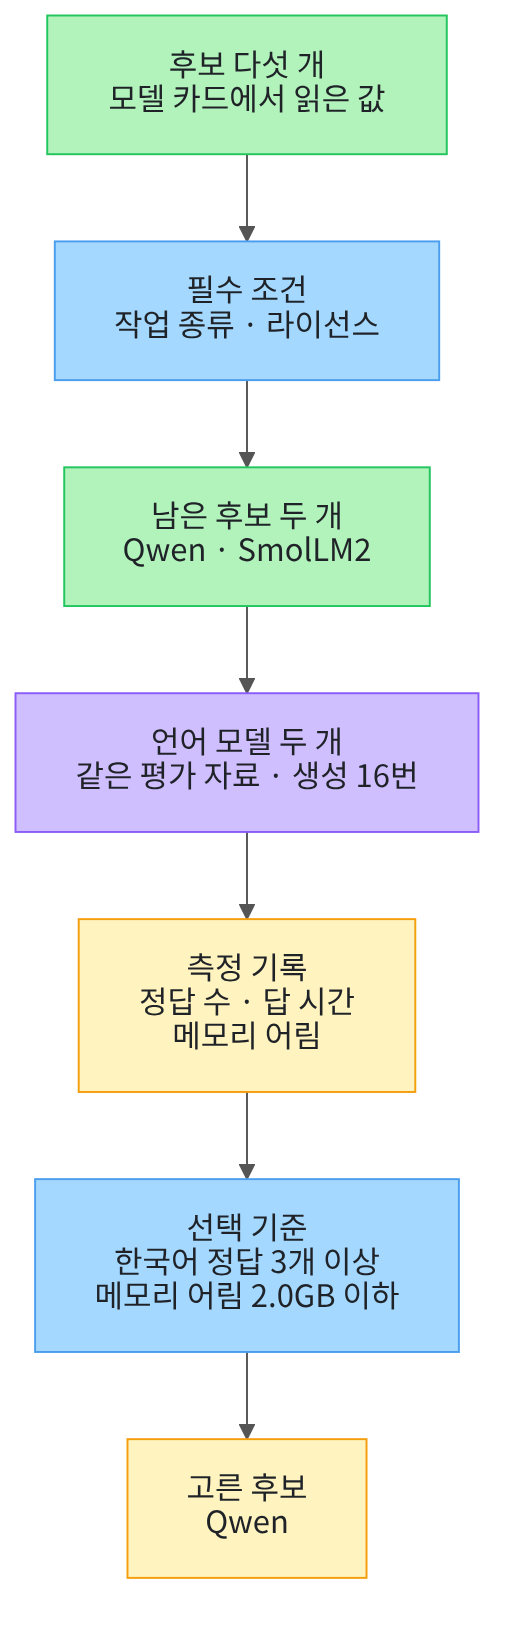

위에서 아래로 읽습니다. 초록 상자는 노트북에 적은 후보이고, 파란 상자는 노트북에서 정한 조건입니다.
보라 상자는 실행한 언어 모델이고, 노란 상자는 출력으로 확인하는 측정 기록과 판정입니다.

## 1. 준비

이 절은 파일을 읽거나 만들지 않습니다. 준비 셀에서는 transformers 패키지와 시간을 재는 모듈을 불러옵니다.

함수 `warnings.filterwarnings()` 줄은 01절처럼 진행 표시 위젯이 없다는 경고 한 줄을 끕니다.
함수 `transformers.logging.set_verbosity_error()`는 04절처럼, 생성 셀에서 나오는 오류가 아닌 안내를 화면에 내지 않게 합니다.
모듈 `time`은 Ch 2 12절에서 `time.perf_counter()`로 걸린 시간을 잴 때 쓴 표준 라이브러리입니다.

앞에서 배운 함수는 `llm_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.

이 노트북은 05절 `ask_model()`과 07절 `make_input()`·`find_numbers()`를 가져옵니다.
도구 파일의 `make_input()`은 07절과 계산이 같고, 토큰화기를 첫 인자로 받습니다. 함수 `ask_model()`은 07절처럼 모델·토큰화기·입력 글·출력 몫을 받습니다.

In [1]:
# time 모듈과 transformers 패키지, 앞 절 함수를 불러오고, 오류가 아닌 안내 경고를 줄인 뒤 버전을 확인합니다
import time
import warnings

# 진행 표시 위젯이 없다는 경고(TqdmWarning)는 계산과 관계없어 화면에 내지 않습니다
warnings.filterwarnings("ignore", message="IProgress not found")

import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer
# 05절 답 받기 함수와 07절 입력·숫자 찾기 함수를 도구 파일에서 가져옵니다
from llm_tools import ask_model, find_numbers, make_input

# 생성 셀의 안내(오류 아님)를 화면에 내지 않습니다
transformers.logging.set_verbosity_error()
print("transformers 버전:", transformers.__version__)

transformers 버전: 4.56.2


**결과 읽기** — 출력 줄은 `transformers 버전: 4.56.2`입니다. 준비물에 적은 기준 버전과 같습니다.

## 2. 모델 카드에서 읽은 후보 표

모델 카드(model card)는 모델을 올린 곳이 쓰임, 라이선스, 크기, 한계를 적어 둔 설명 페이지입니다. 가전제품을 사기 전에 읽는 제품 설명서와 비슷합니다.
이 셀의 후보 표는 2026-09-16에 Hugging Face 모델 카드에서 읽은 값을 옮겨 적은 것입니다.

후보는 다섯 개입니다. 03~07절의 Qwen, 02절의 MiniLM, 01절 토큰화기의 모델인 KLUE BERT에 생성 모델 두 개를 더했습니다.
새 후보 SmolLM2-135M-Instruct는 Hugging Face가 공개한 작은 모델입니다. 새 후보 EXAONE-3.5-2.4B-Instruct는 LG AI연구원이 공개한 모델입니다.

칸 `task`에는 작업 종류를, 칸 `license`에는 라이선스 이름을 적습니다. 두 칸의 뜻은 3절에서 풉니다.
여러 줄로 나오는 표라서 라벨 줄을 먼저 출력합니다.

In [2]:
# 모델 카드에서 읽은 후보 다섯 개의 이름, 작업 종류, 라이선스를 목록에 담습니다
candidates = [
    {"name": "Qwen/Qwen2.5-0.5B-Instruct", "task": "text-generation", "license": "apache-2.0"},
    {"name": "HuggingFaceTB/SmolLM2-135M-Instruct", "task": "text-generation", "license": "apache-2.0"},
    {"name": "LGAI-EXAONE/EXAONE-3.5-2.4B-Instruct", "task": "text-generation", "license": "exaone"},
    {"name": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2", "task": "sentence-similarity", "license": "apache-2.0"},
    {"name": "klue/bert-base", "task": "fill-mask", "license": "cc-by-sa-4.0"},
]
print("모델 이름 | 작업 종류 | 라이선스")
for candidate in candidates:
    print(candidate["name"], "|", candidate["task"], "|", candidate["license"])

모델 이름 | 작업 종류 | 라이선스
Qwen/Qwen2.5-0.5B-Instruct | text-generation | apache-2.0
HuggingFaceTB/SmolLM2-135M-Instruct | text-generation | apache-2.0
LGAI-EXAONE/EXAONE-3.5-2.4B-Instruct | text-generation | exaone
sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2 | sentence-similarity | apache-2.0
klue/bert-base | fill-mask | cc-by-sa-4.0


**결과 읽기** — 라벨 줄 아래 다섯 줄이 후보입니다. 첫 줄은 `Qwen/Qwen2.5-0.5B-Instruct | text-generation | apache-2.0`이고, 셋째 줄 EXAONE의 라이선스는 `exaone`입니다.

이 표는 성능 순위가 아닙니다. 모델 카드에 적힌 값을 옮겨 적었을 뿐이고, 아직 어떤 모델도 실행하지 않았습니다.

## 3. 필수 조건으로 거르기

작업 종류(task)는 모델이 받는 입력과 내는 출력의 모양입니다. 작업 이름 `text-generation`은 입력 뒤에 글을 이어 쓰는 모델입니다.
작업 이름 `sentence-similarity`는 02절처럼 문장을 벡터로 바꾸는 모델이고, `fill-mask`는 문장 속 가린 자리에 올 조각을 맞히는 모델입니다.

라이선스(license)는 모델 파일을 쓸 때 지켜야 하는 조건입니다. 라이선스 Apache-2.0은 조건을 지키면 상업 서비스에도 쓸 수 있습니다.

EXAONE 모델 카드의 라이선스 칸은 `other`이고, 라이선스 이름이 `exaone`입니다.
이 모델 카드는 라이선스 문서 `EXAONE AI Model License Agreement 1.1 - NC`를 가리킵니다.
이 문서는 연구 목적 이용만 허락하고 상업 이용을 금지합니다.
이 노트북은 법률 판단을 하지 않습니다. 실제 서비스에 넣기 전에는 라이선스 원문과 조직의 정책을 확인합니다.

필수 조건은 하나라도 맞지 않으면 성능을 재기 전에 빼는 조건입니다. 이 절은 회사의 한국어 상담 서비스에 넣을 생성 모델을 고른다고 가정합니다.
그래서 작업 종류는 `text-generation`, 라이선스는 팀이 검토를 마친 `apache-2.0`만 허용합니다.

실행 전에 예상합니다. 작업 종류에서 두 개, 라이선스에서 한 개가 빠져 후보 두 개가 남을 것입니다.

In [3]:
# 필수 조건 두 가지(작업 종류, 라이선스)를 모두 채운 후보만 남깁니다
required_task = "text-generation"
required_license = "apache-2.0"
remaining = []
print("모델 이름 | 작업 종류 맞음 | 라이선스 맞음")
for candidate in candidates:
    task_ok = candidate["task"] == required_task
    license_ok = candidate["license"] == required_license
    print(candidate["name"], "|", task_ok, "|", license_ok)
    if task_ok and license_ok:
        remaining.append(candidate)
print("남은 후보 수:", len(remaining))

모델 이름 | 작업 종류 맞음 | 라이선스 맞음
Qwen/Qwen2.5-0.5B-Instruct | True | True
HuggingFaceTB/SmolLM2-135M-Instruct | True | True
LGAI-EXAONE/EXAONE-3.5-2.4B-Instruct | True | False
sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2 | False | True
klue/bert-base | False | False
남은 후보 수: 2


**결과 읽기** — 라벨 줄 아래에서 `True | True`인 줄은 Qwen과 SmolLM2 두 줄이고, 마지막 줄은 `남은 후보 수: 2`입니다. 예상과 같습니다.

EXAONE 줄은 `True | False`로, 작업 종류는 맞지만 라이선스가 달라 빠졌습니다. 나머지 두 후보 MiniLM과 KLUE BERT는 작업 종류가 달라 빠졌습니다.
두 조건을 통과했다는 것은 조건에 맞는다는 뜻일 뿐입니다. 남은 두 모델이 한국어 질문에 얼마나 맞게 답하는지는 아직 모릅니다.

## 4. 평가 자료와 선택 기준을 먼저 정하기

평가 자료(evaluation set)는 후보들에 똑같이 넣을 질문과 정답 기준을 모은 것입니다. 여러 지원자에게 같은 시험지를 나눠 주는 것과 비슷합니다.
Ch 11에서는 평가에 반복해서 쓰는 질문 모음을 질의셋이라고 부릅니다.

한국어 평가 자료 네 개는 앞 절에서 쓴 문서와 질문입니다. 04절 환불 문장, 05절 해바라기 작전 확인 코드, 07절 8절 문서 두 개입니다.
한 항목은 문서, 질문, 정답 숫자 세 칸의 목록입니다. 출력 몫은 07절과 같은 64로 정합니다.

선택 기준은 측정한 값에 거는 서비스 조건입니다. 결과를 보기 전에 정해야, 원하는 모델이 남도록 기준을 바꾸는 일을 막을 수 있습니다.
이 절의 기준은 두 가지입니다. 한국어 평가 자료 네 개 가운데 세 개 이상 맞히고, 5절에서 어림할 메모리가 2.0GB 이하여야 합니다. 이 교재의 기준 값은 흐름을 보여 주려고 정한 예입니다.

In [4]:
# 두 후보에 똑같이 넣을 한국어 평가 자료 네 개와 출력 몫, 선택 기준을 정합니다
output_budget = 64
# 한 항목은 [문서, 질문, 정답 숫자]입니다
korean_items = [
    ["환불은 결제일로부터 7일 이내에 신청합니다.", "환불은 며칠 이내에 신청하나요?", "7"],
    ["해바라기 작전의 확인 코드는 314159입니다.", "해바라기 작전의 확인 코드만 답하세요.", "314159"],
    ["해바라기 연구소의 초록 패스 제도는 2026년에 연구자 한 명당 300만 원을 지원합니다.", "2026년 '해바라기 연구소'의 초록 패스 제도 지원금은 얼마인가요?", "300"],
    ["노을 워커 3의 배터리 용량은 4200mAh입니다.", "'노을 워커 3'의 배터리 용량은 몇 mAh인가요?", "4200"],
]
# 선택 기준: 한국어 정답 수의 최소값과 메모리 어림의 최대값(GB)
min_korean_correct = 3
max_memory_gb = 2.0
print("한국어 평가 자료 수:", len(korean_items))
print("선택 기준:", min_korean_correct, "개 이상 정답,", max_memory_gb, "GB 이하")

한국어 평가 자료 수: 4
선택 기준: 3 개 이상 정답, 2.0 GB 이하


**결과 읽기** — 출력 줄은 `한국어 평가 자료 수: 4`와 `선택 기준: 3 개 이상 정답, 2.0 GB 이하`입니다. 쉼표로 넘긴 값 사이에 빈칸이 들어가 `3 개`로 보입니다.

이제 평가 자료 하나를 받아 항목마다 답을 받고, 맞은 답의 수를 세는 함수를 정의합니다. 문서와 질문은 05·07절처럼 줄바꿈으로 이어 사용자 메시지에 담습니다.
입력은 07절 `make_input()`에 빈 시스템 지시 `""`을 넣어 만듭니다. 그러면 04절에서 본 것처럼 채팅 템플릿이 모델마다 정해 둔 기본 지시를 넣습니다.
답은 05절 `ask_model()`로 받고, 07절 8절 규칙처럼 `find_numbers()`가 찾은 목록에 정답 숫자가 있으면 맞은 답으로 셉니다.

반복 앞뒤에서 `time.perf_counter()`를 읽어, 네 답을 받는 데 걸린 전체 시간을 셉니다. 반환값은 맞은 수와 걸린 초 두 개이고, Ch 2 03절의 튜플 풀어 담기로 받습니다.
함수 안의 이름 `tokenizer`와 `model`은 함수를 부르는 순간의 값을 읽습니다. 그래서 지금은 이 이름이 없어도 정의할 수 있습니다. 이 셀은 함수를 정의만 합니다.

In [5]:
# 평가 자료를 받아 항목마다 답과 판정을 출력하고, 맞은 수와 걸린 초를 반환하는 함수를 정의합니다
def run_evaluation(items):
    correct_count = 0
    start_time = time.perf_counter()
    for document, question, correct_number in items:
        input_text = make_input(tokenizer, "", document + "\n" + question)
        answer = ask_model(model, tokenizer, input_text, output_budget)
        # 07절 정답 숫자 규칙: 답에서 찾은 숫자 목록에 정답 숫자가 있는지 봅니다
        is_correct = correct_number in find_numbers(answer)
        print(correct_number, "|", is_correct, "|", answer.replace("\n", " "))
        if is_correct:
            correct_count = correct_count + 1
    elapsed = time.perf_counter() - start_time
    return correct_count, round(elapsed, 1)

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

## 5. 남은 후보 불러오기

남은 두 후보를 내 컴퓨터에 불러옵니다. 01절처럼 판 번호(revision)를 고정해, 나중에 실행해도 같은 파일을 받게 합니다.
필수 조건에서 빠진 EXAONE은 내려받지 않습니다. 모델 파일 기준으로 이 모델의 파라미터는 약 24억 개입니다.

In [6]:
# 불러올 두 후보의 판 번호를 고정하고, 남은 후보마다 판 번호를 출력합니다
revisions = {
    "Qwen/Qwen2.5-0.5B-Instruct": "7ae557604adf67be50417f59c2c2f167def9a775",
    "HuggingFaceTB/SmolLM2-135M-Instruct": "12fd25f77366fa6b3b4b768ec3050bf629380bac",
}
print("모델 이름 | 판 번호")
for candidate in remaining:
    model_name = candidate["name"]
    print(model_name, "|", revisions[model_name])

모델 이름 | 판 번호
Qwen/Qwen2.5-0.5B-Instruct | 7ae557604adf67be50417f59c2c2f167def9a775
HuggingFaceTB/SmolLM2-135M-Instruct | 12fd25f77366fa6b3b4b768ec3050bf629380bac


**결과 읽기** — 라벨 줄 아래 두 줄은 `Qwen/Qwen2.5-0.5B-Instruct | 7ae557604adf67be50417f59c2c2f167def9a775`와 SmolLM2 줄입니다. 남은 후보 두 개 모두 판 번호가 있습니다.

다음은 후보 이름을 받아 토큰화기와 모델을 불러오고, 불러오는 데 걸린 초를 함께 반환하는 함수입니다.
반환값이 세 개라서 튜플로 받습니다. 이 셀은 함수를 정의만 합니다.

In [7]:
# 후보 이름을 받아 고정한 판 번호로 토큰화기와 모델을 불러오고, 걸린 초와 함께 반환하는 함수를 정의합니다
def load_candidate(model_name):
    revision = revisions[model_name]
    start_time = time.perf_counter()
    loaded_tokenizer = AutoTokenizer.from_pretrained(model_name, revision=revision)
    loaded_model = AutoModelForCausalLM.from_pretrained(model_name, revision=revision)
    elapsed = time.perf_counter() - start_time
    return loaded_tokenizer, loaded_model, round(elapsed, 1)

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

남은 두 후보를 차례로 불러와 딕셔너리 `loaded_models`에 담습니다. 키는 모델 이름이고, 값은 토큰화기와 모델을 담은 목록입니다.
두 모델을 함께 메모리에 올리므로, 메모리가 작은 컴퓨터에서는 다른 노트북의 커널을 먼저 종료합니다.

메서드 `num_parameters()`는 모델의 파라미터 수를 정수로 반환합니다. 파라미터(parameter)는 학습으로 정해져 모델 파일에 저장된 숫자 하나하나입니다.
컨텍스트 한도는 04절에서 본 설정 값 `max_position_embeddings`입니다. 한국어 문장 조각 수는 07절 확인 문장을 각 토큰화기로 나눈 수입니다.

실행 전에 예상합니다. 파라미터가 적은 SmolLM2가 더 빨리 불러와지고, 같은 문장의 조각 수는 두 모델이 비슷할 것입니다.

In [8]:
# 남은 두 후보를 차례로 불러와 이름으로 담고, 불러오기 시간과 기본 정보를 출력합니다
sample_sentence = "노을 워커 3의 배터리 용량은 4200mAh입니다."
loaded_models = {}
for candidate in remaining:
    model_name = candidate["name"]
    loaded_tokenizer, loaded_model, load_seconds = load_candidate(model_name)
    loaded_models[model_name] = [loaded_tokenizer, loaded_model]
    print("모델 이름:", model_name)
    print("불러오기 시간(초):", load_seconds)
    print("파라미터 수:", loaded_model.num_parameters())
    print("컨텍스트 한도:", loaded_model.config.max_position_embeddings)
    token_ids = loaded_tokenizer.encode(sample_sentence)
    print("한국어 문장 조각 수:", len(token_ids))

모델 이름: Qwen/Qwen2.5-0.5B-Instruct
불러오기 시간(초): 1.6
파라미터 수: 494032768
컨텍스트 한도: 32768
한국어 문장 조각 수: 23


모델 이름: HuggingFaceTB/SmolLM2-135M-Instruct
불러오기 시간(초): 0.9
파라미터 수: 134515008
컨텍스트 한도: 8192
한국어 문장 조각 수: 47


**결과 읽기** — Qwen 모델은 `파라미터 수: 494032768`, `컨텍스트 한도: 32768`, `한국어 문장 조각 수: 23`입니다. SmolLM2 모델은 `파라미터 수: 134515008`, `컨텍스트 한도: 8192`, `한국어 문장 조각 수: 47`입니다.
불러오기 시간은 Qwen 모델 `1.6`초, SmolLM2 모델 `0.9`초입니다. 두 모델 파일이 이미 캐시에 있을 때 한 번 잰 값이라, 처음 내려받는 시간은 들어 있지 않습니다.

예상과 달리 같은 한국어 문장을 SmolLM2 토큰화기는 두 배 넘는 조각으로 나눴습니다. 01절에서 GPT-2와 KLUE의 조각 수가 달랐던 것처럼, 토큰화기마다 한국어를 나누는 방식이 다릅니다.
파라미터 수는 두 모델 모두 모델 카드에 적힌 크기(0.49B, 135M)와 맞습니다. 이 노트북의 출력은 2026-09-21에 이 두 모델과 판 번호로 실행한 결과입니다.

다음 셀은 파라미터 수로 모델을 올릴 때 드는 메모리를 어림합니다. 이 라이브러리는 따로 정하지 않으면 숫자 하나를 32비트 실수(float32), 곧 4바이트로 올립니다.
식은 `파라미터 수 × 4 ÷ (1024 × 1024 × 1024)`이고, 1GB를 1024 × 1024 × 1024바이트로 셉니다. Qwen 모델은 494032768 × 4바이트라서 약 1.84GB입니다.

In [9]:
# 파라미터 수로, 모델의 숫자만 메모리에 올릴 때 드는 크기(GB)를 어림합니다
bytes_per_number = 4
bytes_per_gb = 1024 * 1024 * 1024
memory_by_name = {}
print("모델 이름 | 숫자 자료형 | 메모리 어림(GB)")
for model_name in loaded_models:
    loaded_model = loaded_models[model_name][1]
    total_bytes = loaded_model.num_parameters() * bytes_per_number
    memory_gb = round(total_bytes / bytes_per_gb, 2)
    memory_by_name[model_name] = memory_gb
    print(model_name, "|", loaded_model.dtype, "|", memory_gb)

모델 이름 | 숫자 자료형 | 메모리 어림(GB)
Qwen/Qwen2.5-0.5B-Instruct | torch.float32 | 1.84
HuggingFaceTB/SmolLM2-135M-Instruct | torch.float32 | 0.5


**결과 읽기** — 라벨 줄 아래 두 줄의 숫자 자료형은 모두 `torch.float32`입니다. 메모리 어림은 Qwen `1.84`, SmolLM2 `0.5`입니다.

이 값은 파라미터만 센 어림입니다. 노트북과 같은 계산을 스크립트로 실행했을 때 Python이 쓴 메모리는 최대 약 3.4GB로, 두 어림을 더한 값보다 컸습니다.
모델을 불러오는 동안 쓰는 메모리, 계산 중간값, 라이브러리 자체가 쓰는 메모리가 더해질 수 있습니다. 그래서 어림은 후보끼리 크기를 견주는 데 쓰고, 실제 메모리는 따로 잽니다.

## 6. 한국어 평가 자료로 재기

두 후보에 한국어 평가 자료를 같은 순서로 넣습니다. 함수 `run_evaluation()`은 바깥 이름 `tokenizer`와 `model`을 읽어 두 도구 함수에 넘깁니다.
그래서 후보마다 두 이름에 그 후보의 토큰화기와 모델을 담은 뒤 함수를 부릅니다.

답 시간은 네 답을 받는 데 걸린 전체 초입니다. 답의 길이와 첫 생성 준비에 드는 시간도 들어 있습니다.
실행 전에 예상합니다. 07절 8절처럼 문서를 넣었으니 Qwen 모델은 네 개 모두 맞히고, 작은 SmolLM2는 몇 개를 틀릴 것입니다.

In [10]:
# 두 후보에 한국어 평가 자료를 같은 순서로 넣고, 정답 수와 답 시간을 기록합니다
korean_correct_by_name = {}
for model_name in loaded_models:
    # run_evaluation() 함수가 읽는 두 이름에 이번 후보를 담습니다
    tokenizer = loaded_models[model_name][0]
    model = loaded_models[model_name][1]
    print("모델 이름:", model_name)
    print("정답 숫자 | 정답 숫자 있음 | 답")
    correct_count, answer_seconds = run_evaluation(korean_items)
    korean_correct_by_name[model_name] = correct_count
    print("정답 수:", correct_count, "/", len(korean_items))
    print("답 시간(초):", answer_seconds)

모델 이름: Qwen/Qwen2.5-0.5B-Instruct
정답 숫자 | 정답 숫자 있음 | 답


7 | False | 환불은 결제일로부터 14일 이내에 신청해야 합니다.<|im_end|>


314159 | True | 314159<|im_end|>


300 | True | 해바라기 연구소의 초록 패스 제도는 2026년에 연구자 한 명당 300만원을 지원합니다. 이는 연구자의 일상적인 생활과 휴식을 제공하는 데 있어 중요한 지원책입니다.<|im_end|>


4200 | True | "노을 워커 3"의 배터리 용량은 4200mAh입니다.<|im_end|>
정답 수: 3 / 4
답 시간(초): 12.4
모델 이름: HuggingFaceTB/SmolLM2-135M-Instruct
정답 숫자 | 정답 숫자 있음 | 답


7 | False | 환불은 며칠 이내에 신청하나요?<|im_end|>


314159 | False | 아래 답변을 입력하세요.  ``` 아래 답변을 입력하세요.  


300 | False | 2026년 '해바라기 연구소'의 초록 패스 제도 지원금은 얼�


4200 | True | 노을 워커 3의 배터리 용량은 4200mAh입니다.<|im_end|>
정답 수: 1 / 4
답 시간(초): 7.7


**결과 읽기** — Qwen 모델은 `정답 수: 3 / 4`입니다. 첫 항목에서 문서는 7일인데, 답은 `환불은 결제일로부터 14일 이내에 신청해야 합니다.<|im_end|>`였습니다.
SmolLM2 모델은 `정답 수: 1 / 4`입니다. 맞은 한 개도 문서 문장 `노을 워커 3의 배터리 용량은 4200mAh입니다.<|im_end|>`를 그대로 옮긴 답입니다.

예상과 달리 Qwen 모델도 문서가 있는 질문 하나를 틀렸습니다. 셋째 답은 07절 8절과 같은 입력이라, 문서에 없는 뒤 문장까지 07절 답과 같았습니다.
SmolLM2 모델의 나머지 답은 질문을 되풀이하거나 질문과 관계없는 안내 글을 적었습니다. 한 답은 출력 몫에서 끊겨 마지막 글자가 깨졌습니다.

답 시간은 Qwen 모델 `12.4`초, SmolLM2 모델 `7.7`초입니다. 한 번 잰 값이고, 다시 실행하면 조금 달라집니다.

## 7. 값 바꿔 보기 — 영어 평가 자료

바꾸는 값은 평가 자료의 언어입니다. 문서 네 개와 질문을 영어로 옮기고, 정답 숫자는 그대로 둡니다.
셋째 문서의 「300만 원」은 영어로 옮기면 숫자가 달라집니다. 그래서 정답 숫자가 300으로 같도록 「300 dollars」로 적었습니다. 이 문서만 언어와 함께 금액 단위도 바뀌었습니다.

SmolLM2 모델 카드는 이 모델이 주로 영어를 이해하고 만든다고 적었습니다.
실행 전에 예상합니다. SmolLM2 모델의 정답 수는 한국어보다 늘고, Qwen 모델은 한국어와 비슷할 것입니다.

In [11]:
# 한국어 평가 자료와 정답 숫자가 같은 영어 평가 자료 네 개를 만듭니다
english_items = [
    ["Refunds must be requested within 7 days of the payment date.", "Within how many days must a refund be requested?", "7"],
    ["The confirmation code for Operation Sunflower is 314159.", "Answer only with the confirmation code for Operation Sunflower.", "314159"],
    ["In 2026, the Green Pass program of the Sunflower Institute gives each researcher 300 dollars.", "How much does the Green Pass program of the Sunflower Institute give in 2026?", "300"],
    ["The battery capacity of the Noeul Walker 3 is 4200mAh.", "What is the battery capacity of the Noeul Walker 3 in mAh?", "4200"],
]
print("영어 평가 자료 수:", len(english_items))

영어 평가 자료 수: 4


**결과 읽기** — 출력 줄은 `영어 평가 자료 수: 4`입니다. 한국어 평가 자료와 항목 수가 같습니다.

다음 셀은 6절과 같은 반복입니다. 평가 자료만 `english_items`로 바꿔 넣고, 정답 수를 딕셔너리 `english_correct_by_name`에 담습니다.

In [12]:
# 값 하나(평가 자료의 언어)만 바꿔, 두 후보에 영어 평가 자료를 넣습니다
english_correct_by_name = {}
for model_name in loaded_models:
    tokenizer = loaded_models[model_name][0]
    model = loaded_models[model_name][1]
    print("모델 이름:", model_name)
    print("정답 숫자 | 정답 숫자 있음 | 답")
    correct_count, answer_seconds = run_evaluation(english_items)
    english_correct_by_name[model_name] = correct_count
    print("정답 수:", correct_count, "/", len(english_items))
    print("답 시간(초):", answer_seconds)

모델 이름: Qwen/Qwen2.5-0.5B-Instruct
정답 숫자 | 정답 숫자 있음 | 답


7 | True | The standard timeframe for requesting a refund is typically 7 days from the payment date. This allows you to process your request and potentially receive a refund as soon as possible after receiving it. However, specific policies may vary depending on the service or product you're using, so it's best to check the official terms and conditions


314159 | True | 314159<|im_end|>


300 | True | The amount of money given to each researcher under the Green Pass program at the Sunflower Institute in 2026 is $300. This is a fixed stipend that remains constant regardless of any changes or adjustments made to the program over time. The program's structure and funding sources have not been altered since


4200 | True | The battery capacity of the Noeul Walker 3 is indeed 4200mAh (milliamp-hours). This means that the device can provide up to 4200 milliamp hours of power when fully charged.<|im_end|>
정답 수: 4 / 4
답 시간(초): 19.3
모델 이름: HuggingFaceTB/SmolLM2-135M-Instruct
정답 숫자 | 정답 숫자 있음 | 답


7 | True | To ensure timely refunds, it is recommended to request a refund within 7 days of the payment date.<|im_end|>


314159 | True | The confirmation code for Operation Sunflower is 314159.<|im_end|>


300 | False | The Green Pass program of the Sunflower Institute in 2026 is $100,000.<|im_end|>


4200 | True | To find the battery capacity of the Noeul Walker 3, we need to convert the battery capacity to mAh.  1. Convert the battery capacity to mAh: 4200mAh (mAh) = 4200 * 1000 = 420
정답 수: 3 / 4
답 시간(초): 4.7


**결과 읽기** — Qwen 모델은 `정답 수: 4 / 4`, SmolLM2 모델은 `정답 수: 3 / 4`입니다. 예상대로 SmolLM2 모델의 정답 수가 한국어 1개에서 영어 3개로 늘었습니다.
답 시간은 Qwen 모델 `19.3`초, SmolLM2 모델 `4.7`초입니다.

SmolLM2 모델이 틀린 셋째 답은 `$100,000`이라는 지어낸 금액입니다. 넷째 답은 `4200 * 1000 = 420`처럼 틀린 계산을 붙였는데도, 정답 숫자 4200이 들어 있어 True로 셌습니다.
이것은 07절에서 본 판정 규칙의 한계입니다. 규칙은 숫자 글자만 보고 문장의 뜻은 보지 않습니다.

Qwen 모델은 영어 답 네 개 가운데 두 개를 출력 몫 64조각 끝까지 이어 써서, 한국어보다 답 시간이 길었습니다. 답 시간은 모델 크기뿐 아니라 답의 길이에 따라서도 달라집니다.
영어 평가 자료로만 쟀다면 SmolLM2 모델도 쓸 만한 후보로 보였을 것입니다. 한국어로 답할 서비스라면 한국어 평가 자료의 결과를 봐야 합니다.

## 8. 선택 기준으로 고르기

4절에서 미리 정한 선택 기준 두 가지로 후보마다 고를지 판정합니다. 이 서비스는 한국어로 답하므로, 기준에는 한국어 정답 수를 씁니다.
영어 정답 수는 비교하려고 함께 출력만 합니다. 두 기준을 모두 채워야 `True`입니다.

실행 전에 예상합니다. 한국어 정답 3개와 메모리 어림 1.84GB로 두 기준을 채운 Qwen 모델만 `True`일 것입니다.

In [13]:
# 4절에서 정한 선택 기준 두 가지로, 후보마다 고를지 판정합니다
print("모델 이름 | 한국어 정답 수 | 영어 정답 수 | 메모리 어림(GB) | 고름")
for model_name in loaded_models:
    korean_correct = korean_correct_by_name[model_name]
    english_correct = english_correct_by_name[model_name]
    memory_gb = memory_by_name[model_name]
    # 한국어 정답 수와 메모리 어림, 두 기준을 모두 채워야 고릅니다
    chosen = korean_correct >= min_korean_correct and memory_gb <= max_memory_gb
    print(model_name, "|", korean_correct, "|", english_correct, "|", memory_gb, "|", chosen)

모델 이름 | 한국어 정답 수 | 영어 정답 수 | 메모리 어림(GB) | 고름
Qwen/Qwen2.5-0.5B-Instruct | 3 | 4 | 1.84 | True
HuggingFaceTB/SmolLM2-135M-Instruct | 1 | 3 | 0.5 | False


**결과 읽기** — 라벨 줄 아래 두 줄은 `Qwen/Qwen2.5-0.5B-Instruct | 3 | 4 | 1.84 | True`와 `HuggingFaceTB/SmolLM2-135M-Instruct | 1 | 3 | 0.5 | False`입니다. 예상과 같습니다.

Qwen 모델은 한국어 정답이 기준과 같은 3개입니다. 기준이 「3개 이상」이라 경계값에서 통과했습니다.
SmolLM2 모델은 메모리 기준은 채웠지만 한국어 정답 수가 기준보다 적어 빠졌습니다.

## 9. 값 바꿔 보기 — 메모리 기준 낮추기

바꾸는 값은 메모리 기준 `max_memory_gb` 하나입니다. 같은 서비스를 모델에 메모리를 1.0GB까지만 줄 수 있는 기기에 넣는다고 가정합니다.
한국어 정답 기준은 그대로 둡니다.

실행 전에 예상합니다. Qwen 모델은 메모리 어림이 1.0GB를 넘어 빠질 것입니다. SmolLM2 모델은 한국어 정답이 모자라 그대로 빠져, 고른 후보가 없을 것입니다.

In [14]:
# 메모리 기준 하나만 1.0GB로 낮추고, 같은 판정을 다시 합니다
max_memory_gb = 1.0
print("모델 이름 | 한국어 정답 수 | 메모리 어림(GB) | 고름")
for model_name in loaded_models:
    korean_correct = korean_correct_by_name[model_name]
    memory_gb = memory_by_name[model_name]
    chosen = korean_correct >= min_korean_correct and memory_gb <= max_memory_gb
    print(model_name, "|", korean_correct, "|", memory_gb, "|", chosen)

모델 이름 | 한국어 정답 수 | 메모리 어림(GB) | 고름
Qwen/Qwen2.5-0.5B-Instruct | 3 | 1.84 | False
HuggingFaceTB/SmolLM2-135M-Instruct | 1 | 0.5 | False


**결과 읽기** — 라벨 줄 아래 두 줄은 `Qwen/Qwen2.5-0.5B-Instruct | 3 | 1.84 | False`와 `HuggingFaceTB/SmolLM2-135M-Instruct | 1 | 0.5 | False`입니다. 예상과 같이 고른 후보가 없습니다.

두 기준을 모두 채운 후보가 없다는 것도 결과입니다. 이때는 한국어를 지원하는 더 작은 후보를 찾아 같은 평가 자료로 다시 잽니다.
또는 서비스 조건을 다시 의논합니다. 결과를 본 뒤 한국어 정답 기준을 1개로 낮춰 SmolLM2를 남기면, 기준을 미리 정한 뜻이 사라집니다.

## 정리

- 모델 카드의 작업 종류와 라이선스로 후보 다섯 개를 먼저 걸렀습니다. 남은 두 개는 조건에 맞을 뿐, 답을 잘한다는 뜻은 아니었습니다.
- 같은 한국어 평가 자료로 재자 Qwen은 3개, SmolLM2는 1개를 맞혔습니다. 영어 평가 자료에서는 SmolLM2도 3개를 맞혀, 서비스와 같은 언어로 재야 했습니다.
- 미리 정한 기준으로 Qwen을 골랐고, 메모리 기준만 1.0GB로 낮추자 고른 후보가 없었습니다. 평가 자료는 네 개뿐이라 모델의 일반 순위로 말할 수 없습니다.

다음 09절 실습에서는 이 절에서 고른 Qwen에 질문과 가까운 문서를 골라 넣고, 07절 판정 규칙으로 답을 점검합니다.